# 02 — Stationnarité, ARIMA et variables explicatives (Membre 2)

**Problématique :** comment prévoir la consommation annuelle d'électricité résidentielle en France à partir des observations historiques ?

Ce notebook couvre la partie *stochastique* du projet sur la série nationale à périmètre constant (`conso_twh_pc`, 2018–2025) :
1. les tests de stationnarité (ADF, KPSS) et les corrélogrammes (ACF, PACF) ;
2. l'identification et l'estimation de modèles AR, ARIMA et ARIMA avec dérive, avec choix par AIC, AICc et BIC ;
3. le diagnostic des résidus (Ljung-Box, ACF des résidus) ;
4. une régression avec une variable explicative de **rupture 2022** (sobriété) et la place prévue pour les **degrés-jours unifiés** (DJU) ;
5. la prévision 2026 avec intervalles de confiance à 80 % et 95 %.

> ⚠️ **Limite structurelle :** la série compte 8 points annuels, dont 7 pour l'entraînement. Les tests ont une puissance très faible et les critères d'information sont instables. Il faut le dire explicitement dans le rapport : les résultats indiquent une tendance, ils ne prouvent rien. C'est aussi pourquoi le notebook 03 exploite la dimension adresse.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import PROCESSED, FIGURES, TRAIN_FIN, TEST_ANNEES
from src.metrics import BASELINES, tableau_scores, origine_glissante, rmse, mae, mape
from src.plotting import COULEURS, style, source

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

fr = duckdb.sql(f"select * from '{(PROCESSED / 'france_annuel.parquet').as_posix()}' order by annee").df()
annees = fr["annee"].to_numpy()

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.simplefilter("ignore")   # avertissements statsmodels attendus sur séries très courtes
y = fr["conso_twh_pc"].to_numpy()
train = annees <= TRAIN_FIN
y_tr = y[train]

ImportError: DLL load failed while importing _duckdb: Une stratégie de contrôle d’application a bloqué ce fichier.

## 1. Pas de composante saisonnière

Les données sont **annuelles** : il n'y a pas de saisonnalité à l'intérieur de l'année (s = 1). SARIMA et TBATS sont donc écartés. La saisonnalité de la consommation (hiver/été) n'existe qu'en données mensuelles, par exemple les séries RTE. Elle ne peut pas apparaître ici.

## 2. Tests de stationnarité

- **ADF :** H0 = racine unitaire (série non stationnaire).
- **KPSS :** H0 = série stationnaire.

On applique les deux tests au niveau et à la différence première, sur l'échantillon d'entraînement seulement. Avec 7 points, on limite le nombre de retards à 0 ou 1.

In [ ]:
def tests(s, nom):
    warnings.simplefilter("ignore")
    out = {"série": nom}
    for ml in (0, 1):
        out[f"ADF p (retards={ml})"] = adfuller(s, maxlag=ml, autolag=None, regression="c")[1]
    out["KPSS p"] = kpss(s, regression="c", nlags=1)[1]
    return out

pd.DataFrame([tests(y_tr, "niveau"), tests(np.diff(y_tr), "différence 1")]).set_index("série")

,ADF p (retards=0),ADF p (retards=1),KPSS p
série,,,
niveau,0.849,0.877,0.087
différence 1,0.338,0.474,0.100


**Lecture.**
- En niveau, ADF ne rejette pas la racine unitaire (p ≈ 0,85). KPSS rejette la stationnarité au seuil de 10 % (p ≈ 0,09). Les deux tests vont dans le même sens : **le niveau n'est pas stationnaire**.
- En différence première, KPSS ne rejette plus la stationnarité (p ≥ 0,10). ADF reste non significatif, mais sa puissance est quasi nulle avec 6 points.
- **Conclusion :** on retient **d = 1**, ce qui est cohérent avec le notebook 01, où le lissage exponentiel optimal a α ≈ 1, comme une marche aléatoire.

*Remarque : KPSS borne ses p-valeurs à l'intervalle [0,01 ; 0,10]. Une valeur de 0,10 signifie « p ≥ 0,10 ».*

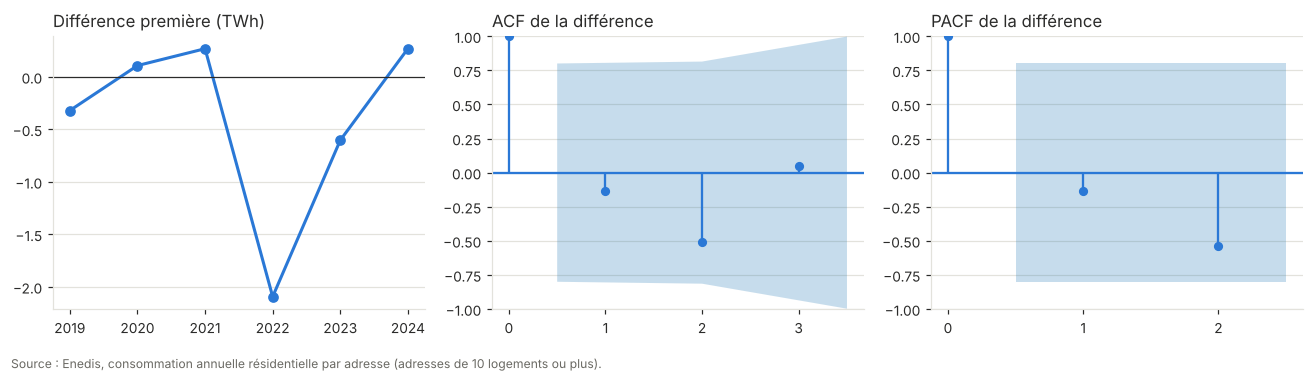

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
axs[0].plot(annees[train][1:], np.diff(y_tr), "o-", color=COULEURS[0], lw=2)
axs[0].axhline(0, color="#2b2b2a", lw=.8); axs[0].set_xticks(annees[train][1:])
style(axs[0], "Différence première (TWh)")
plot_acf(np.diff(y_tr), lags=3, ax=axs[1], title="", color=COULEURS[0], vlines_kwargs={"colors": COULEURS[0]})
plot_pacf(np.diff(y_tr), lags=2, ax=axs[2], title="", method="ywm", color=COULEURS[0], vlines_kwargs={"colors": COULEURS[0]})
style(axs[1], "ACF de la différence"); style(axs[2], "PACF de la différence")
axs[1].set_xticks(range(4)); axs[2].set_xticks(range(3))
source(fig); fig.tight_layout(rect=(0, .05, 1, 1)); plt.show()

**Lecture.** Aucune autocorrélation ne sort de la bande de confiance : la différence première ressemble à un **bruit blanc**. Le modèle le plus simple compatible avec ces observations est donc **ARIMA(0,1,0)**, soit une marche aléatoire, éventuellement avec dérive. C'est exactement la prévision naïve.

## 3. Estimation de modèles candidats

On compare plusieurs modèles parcimonieux. Attention : **l'AIC n'est comparable qu'entre modèles de même ordre d'intégration d**, car la différenciation change l'échantillon utilisé pour la vraisemblance. Avec si peu de points, on regarde l'**AICc** (AIC corrigé pour les petits échantillons).

In [ ]:
candidats = {
    "ARIMA(0,1,0)":            dict(order=(0, 1, 0), trend="n"),
    "ARIMA(0,1,0) + dérive":   dict(order=(0, 1, 0), trend="t"),
    "ARIMA(0,1,1)":            dict(order=(0, 1, 1), trend="n"),
    "ARIMA(1,1,0)":            dict(order=(1, 1, 0), trend="n"),
    "AR(1) + constante":       dict(order=(1, 0, 0), trend="c"),
}

lignes = []
for nom, kw in candidats.items():
    m = ARIMA(y_tr, **kw).fit()
    res = m.resid[kw["order"][1]:]          # retire le 1er résidu (non défini en d=1)
    lignes.append({"modèle": nom, "d": kw["order"][1], "AIC": m.aic, "AICc": m.aicc, "BIC": m.bic,
                   "sigma": np.sqrt(m.params[-1]),
                   "Ljung-Box p (2 retards)": acorr_ljungbox(res, lags=[2])["lb_pvalue"].iloc[0]})
pd.DataFrame(lignes).set_index("modèle").sort_values(["d", "AICc"])

,d,AIC,AICc,BIC,sigma,Ljung-Box p (2 retards)
modèle,,,,,,
AR(1) + constante,0,24.017,32.017,23.854,0.839,0.840
"ARIMA(0,1,0)",1,17.938,18.938,17.729,0.913,0.194
"ARIMA(0,1,0) + dérive",1,18.692,22.692,18.276,0.823,0.194
"ARIMA(0,1,1)",1,19.831,23.831,19.415,0.903,0.222
"ARIMA(1,1,0)",1,19.877,23.877,19.460,0.908,0.200


**Lecture.**
- Parmi les modèles avec d = 1, **ARIMA(0,1,0)** a le plus petit AICc. Ajouter une dérive, un terme MA ou un terme AR n'améliore pas l'ajustement assez pour justifier un paramètre de plus.
- L'AR(1) en niveau (d = 0) a l'AICc le plus élevé. Il suppose un retour vers une moyenne de long terme, ce qui ne colle pas à une série qui a changé de niveau.
- Le test de Ljung-Box ne rejette jamais la blancheur des résidus. Avec 6 résidus, ce test a toutefois peu de puissance.

## 4. Variable explicative de rupture : la sobriété de 2022

La série a deux régimes : avant 2022 et après 2022. On teste une **régression à erreurs ARMA** (ARIMAX) avec une indicatrice $D_t = \mathbb{1}\{t \geq 2022\}$ :

$$y_t = \mu + \delta\, D_t + u_t, \qquad u_t \sim \text{ARMA}(p, 0)$$

**Avertissement méthodologique :** la date de la rupture est choisie *a posteriori*, en regardant les données. En situation réelle, au 1er janvier 2022, personne ne pouvait la connaître. Ce modèle **explique** le passé, mais il n'aurait pas pu **prévoir** 2022. Il est légitime pour prévoir 2025 et 2026 si l'on fait l'hypothèse que le nouveau régime persiste.

In [ ]:
D = (annees >= 2022).astype(float)
modeles_x = {}
for nom, order in {"Rupture 2022 + bruit blanc": (0, 0, 0), "Rupture 2022 + AR(1)": (1, 0, 0)}.items():
    m = ARIMA(y_tr, exog=D[train], order=order, trend="c").fit()
    modeles_x[nom] = m
    print(f"--- {nom}   AICc = {m.aicc:.1f}")
    print(m.summary().tables[1])

--- Rupture 2022 + bruit blanc   AICc = 11.3
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         21.3329      0.129    165.082      0.000      21.080      21.586
x1            -2.2307      0.160    -13.917      0.000      -2.545      -1.917
sigma2         0.0395      0.034      1.157      0.247      -0.027       0.107
--- Rupture 2022 + AR(1)   AICc = 25.0
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         21.3330      0.112    190.283      0.000      21.113      21.553
x1            -2.2360      0.285     -7.854      0.000      -2.794      -1.678
ar.L1         -0.1727      0.869     -0.199      0.842      -1.876       1.530
sigma2         0.0381      0.047      0.803      0.422      -0.055       0.131


In [ ]:
m = modeles_x["Rupture 2022 + bruit blanc"]
mu, delta = m.params[0], m.params[1]
print(f"Niveau avant 2022 : {mu:.2f} TWh ; après : {mu + delta:.2f} TWh ; "
      f"rupture = {delta:.2f} TWh ({100 * delta / mu:.1f} %)")
print(f"Ljung-Box p (2 retards) = {acorr_ljungbox(m.resid, lags=[2])['lb_pvalue'].iloc[0]:.2f}")

Niveau avant 2022 : 21.33 TWh ; après : 19.10 TWh ; rupture = -2.23 TWh (-10.5 %)
Ljung-Box p (2 retards) = 0.19


**Lecture.** La rupture est estimée à environ −2,2 TWh, soit −10,5 %, et elle est très significative. Une fois cette marche prise en compte, les écarts restants sont faibles (σ ≈ 0,2 TWh) et sans autocorrélation. La série se décrit donc bien comme **deux plateaux séparés par un choc**, plutôt que comme une tendance.

### Place prévue pour les degrés-jours unifiés (DJU)

La consommation résidentielle dépend fortement de la température, à cause du chauffage. L'hiver 2022-2023 a été doux, ce qui se confond en partie avec l'effet de la sobriété. Pour séparer les deux effets, il faut une série annuelle de **DJU chauffage** pour la France métropolitaine, par exemple les données du SDES ou de Météo-France.

Déposer un fichier `data/raw/dju_annuels.csv` avec deux colonnes, `annee` et `dju`. La cellule suivante l'utilisera automatiquement. Attention : pour prévoir 2026, il faudra une hypothèse sur les DJU 2026, par exemple une année climatique normale.

In [ ]:
f_dju = ROOT / "data" / "raw" / "dju_annuels.csv"
if f_dju.exists():
    dju = pd.read_csv(f_dju).set_index("annee").loc[annees, "dju"].to_numpy(float)
    X = np.column_stack([D, dju])
    m_dju = ARIMA(y_tr, exog=X[train], order=(0, 0, 0), trend="c").fit()
    print(m_dju.summary().tables[1])
    p = m_dju.get_forecast(1, exog=X[~train]).predicted_mean[0]
    print(f"Prévision 2025 : {p:.3f} TWh (observé {y[~train][0]:.3f})")
else:
    print("Pas de fichier DJU : étape à faire (voir cellule précédente).")

Pas de fichier DJU : étape à faire (voir cellule précédente).


## 5. Évaluation selon le protocole commun

On reprend le même protocole que le notebook 01 : prévision de 2025 avec un entraînement sur 2018–2024, et validation à origine glissante. Le modèle de rupture n'est estimable qu'à partir de la prévision 2023, puisqu'il faut au moins une année après 2022 dans l'échantillon d'entraînement. On l'évalue donc sur 2023–2025, et on recalcule la prévision naïve sur la même fenêtre pour une comparaison équitable.

In [ ]:
def f_arima(order, trend):
    def f(h):
        warnings.simplefilter("ignore")
        return float(ARIMA(np.asarray(h), order=order, trend=trend).fit().forecast(1)[0])
    return f

def f_rupture(h):
    n = len(h); a = annees[:n]
    Dh = (a >= 2022).astype(float); Dn = np.array([[float(annees[n] >= 2022)]])
    return float(ARIMA(np.asarray(h), exog=Dh, order=(0, 0, 0), trend="c").fit().forecast(1, exog=Dn)[0])

modeles_arima = {"Naïf (y_t)": BASELINES["Naïf (y_t)"]}
modeles_arima.update({nom: f_arima(kw["order"], kw["trend"]) for nom, kw in candidats.items()})
s21 = tableau_scores(annees, y, modeles_arima, debut_glissant=2021)
s23 = tableau_scores(annees, y, {"Naïf (y_t)": BASELINES["Naïf (y_t)"],
                                 "ARIMA(0,1,0)": modeles_arima["ARIMA(0,1,0)"],
                                 "Rupture 2022 + bruit blanc": f_rupture}, debut_glissant=2023)
print("Validation glissante 2021–2025 :"); display(s21)
print("Validation glissante 2023–2025 (après la rupture) :"); display(s23)
s21.to_csv(PROCESSED / "scores_membre2.csv")

Validation glissante 2021–2025 :


,prévision 2025,observé,erreur test (%),RMSE glissant,MAE glissant,MAPE glissant (%)
modèle,,,,,,
Naïf (y_t),19.080,18.993,0.461,0.990,0.664,3.421
"ARIMA(0,1,0)",19.080,18.993,0.461,0.990,0.664,3.421
"ARIMA(0,1,0) + dérive",18.685,18.993,-1.621,1.033,0.737,3.783
"ARIMA(0,1,1)",19.133,18.993,0.739,1.088,0.809,4.198
"ARIMA(1,1,0)",19.106,18.993,0.594,1.163,0.872,4.514
AR(1) + constante,19.490,18.993,2.620,1.669,1.230,6.437


Validation glissante 2023–2025 (après la rupture) :


,prévision 2025,observé,erreur test (%),RMSE glissant,MAE glissant,MAPE glissant (%)
modèle,,,,,,
Naïf (y_t),19.080,18.993,0.461,0.385,0.320,1.693
"ARIMA(0,1,0)",19.080,18.993,0.461,0.385,0.320,1.693
Rupture 2022 + bruit blanc,19.102,18.993,0.575,0.354,0.248,1.318


**Lecture.**
- ARIMA(0,1,0) donne exactement la même prévision que le naïf, ce qui confirme que **la prévision naïve est le modèle ARIMA optimal** pour cette série.
- Les variantes avec dérive ou termes AR/MA font moins bien en validation glissante. L'AR(1) en niveau rappelle la série vers sa moyenne d'avant 2022, ce qui est pénalisant après la rupture.
- Le modèle de rupture fait au moins aussi bien que le naïf sur 2023–2025, avec des intervalles beaucoup plus étroits. Il repose toutefois sur l'hypothèse que le nouveau régime persiste.

## 6. Diagnostic des résidus du modèle retenu (ARIMA(0,1,0), estimé sur 2018–2025)

Ljung-Box p (2 retards) = 0.20
Shapiro-Wilk p = 0.02   (normalité, puissance très faible avec 7 points)


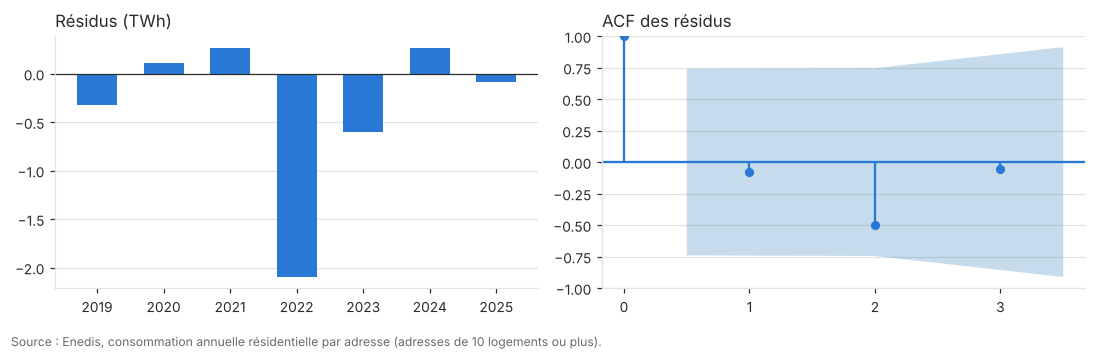

In [ ]:
from scipy import stats
m_final = ARIMA(y, order=(0, 1, 0), trend="n").fit()
res = m_final.resid[1:]
print(f"Ljung-Box p (2 retards) = {acorr_ljungbox(res, lags=[2])['lb_pvalue'].iloc[0]:.2f}")
print(f"Shapiro-Wilk p = {stats.shapiro(res).pvalue:.2f}   (normalité, puissance très faible avec 7 points)")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].bar(annees[1:], res, color=COULEURS[0], width=.6); axs[0].axhline(0, color="#2b2b2a", lw=.8)
axs[0].set_xticks(annees[1:]); style(axs[0], "Résidus (TWh)")
plot_acf(res, lags=3, ax=axs[1], title="", color=COULEURS[0], vlines_kwargs={"colors": COULEURS[0]})
style(axs[1], "ACF des résidus"); axs[1].set_xticks(range(4))
source(fig); fig.tight_layout(rect=(0, .05, 1, 1)); plt.show()

**Lecture.** Les résidus ne sont pas autocorrélés. En revanche, ils sont dominés par le choc de 2022 (≈ −2,1 TWh). Avec une marche aléatoire, ce choc gonfle la variance estimée, donc la largeur des intervalles de confiance. C'est le prix à payer pour un modèle qui ne présuppose pas la persistance du nouveau régime. Le test de Shapiro-Wilk rejette la normalité (p ≈ 0,02), toujours à cause de 2022 : les intervalles gaussiens ci-dessous sont donc approximatifs.

## 7. Prévision 2026 avec intervalles de confiance à 80 % et 95 %

In [ ]:
an_f = annees[-1] + 1
lignes, bandes = [], {}
m_rw = ARIMA(y, order=(0, 1, 0), trend="n").fit()
m_ru = ARIMA(y, exog=D, order=(0, 0, 0), trend="c").fit()
for nom, mm, kw in [("ARIMA(0,1,0)", m_rw, {}), ("Rupture 2022 + bruit blanc", m_ru, {"exog": [[1.0]]})]:
    f = mm.get_forecast(1, **kw)
    i80, i95 = f.conf_int(alpha=.20)[0], f.conf_int(alpha=.05)[0]
    bandes[nom] = (f.predicted_mean[0], i80, i95)
    lignes.append({"modèle": nom, f"prévision {an_f} (TWh)": f.predicted_mean[0],
                   "IC 80 %": f"[{i80[0]:.2f} ; {i80[1]:.2f}]", "IC 95 %": f"[{i95[0]:.2f} ; {i95[1]:.2f}]"})
pd.DataFrame(lignes).set_index("modèle")

,prévision 2026 (TWh),IC 80 %,IC 95 %
modèle,,,
"ARIMA(0,1,0)",18.993,[17.91 ; 20.08],[17.33 ; 20.65]
Rupture 2022 + bruit blanc,19.075,[18.83 ; 19.32],[18.70 ; 19.45]


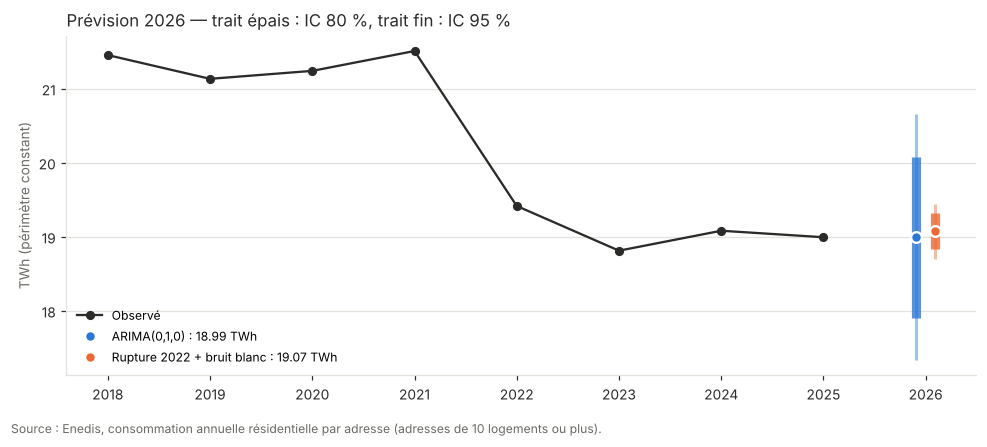

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(annees, y, "o-", color="#2b2b2a", lw=1.5, ms=5, label="Observé")
for i, (nom, (p, i80, i95)) in enumerate(bandes.items()):
    x = an_f + (i - .5) * 0.18
    ax.vlines(x, *i95, color=COULEURS[i], lw=2, alpha=.45)
    ax.vlines(x, *i80, color=COULEURS[i], lw=6, alpha=.8)
    ax.plot(x, p, "o", color=COULEURS[i], ms=7, mec="white", mew=1.5, label=f"{nom} : {p:.2f} TWh")
ax.set_xticks(list(annees) + [an_f]); ax.legend(frameon=False, fontsize=8, loc="lower left")
style(ax, f"Prévision {an_f} — trait épais : IC 80 %, trait fin : IC 95 %", "TWh (périmètre constant)")
source(fig); fig.tight_layout(rect=(0, .04, 1, 1)); plt.show()

## Conclusions pour le rapport

1. **d = 1 :** la série en niveau n'est pas stationnaire (ADF et KPSS concordent). La différence première se comporte comme un bruit blanc.
2. **ARIMA(0,1,0)**, la marche aléatoire, est le modèle retenu par l'AICc et la validation glissante. Il coïncide avec la prévision naïve, qu'aucun ARIMA plus riche ne bat.
3. La série se lit mieux comme **deux régimes**, avant et après 2022. Un modèle à rupture donne la même prévision centrale que la marche aléatoire, environ 19 TWh, mais avec un intervalle de confiance environ 4 fois plus étroit. Il fait cependant l'hypothèse que le nouveau régime persiste.
4. **À faire :** ajouter les DJU pour séparer l'effet de la météo de celui de la sobriété, puis tester la sensibilité de la prévision 2026 à un hiver froid ou doux.